# 【簡約版】Stable Diffusion 1.5 推論パイプライン入門

> 本記事は『Stable Diffusion 1.5 推論パイプライン入門』の簡約版です。各トピックの詳細な解説は本編をご参照ください。

（TODO: 本編の URL。公開後に記載）

Attention や残差接続など、GPT-2 と共通する概念は説明を省いています。先に『【簡約版】GPT-2 推論エンジン入門』を読んでおくことを推奨します。

https://zenn.dev/7shi/articles/20260330-gpt2-inference

# Stable Diffusion 1.5 とは

Stable Diffusion 1.5（以下 SD 1.5）は、2022 年に公開された、テキストから画像を生成するモデルです。GPT-2 が「次のトークンを予測する」ことを繰り返してテキストを生成するのに対し、SD 1.5 は「ノイズを少しずつ取り除く」ことを繰り返して画像を生成します。このようなモデルを**拡散モデル**と呼びます。

SD 1.5 は 1 つのネットワークではなく、役割の異なる 3 つのネットワークの組み合わせです。

| コンポーネント | 役割 | パラメーター数 |
|---|---|---|
| CLIP Text Encoder | テキストを条件ベクトルに変換する | 約 123M |
| U-Net | 条件ベクトルを参照して、ノイズを予測する | 約 860M |
| VAE Decoder | 潜在表現をピクセル画像に変換する | 約 50M |

SD 1.5 には、同じ構造のまま重みだけを学習し直した派生モデルが数多くあります。本ノートブックでは CPU で動かすため、256×256 向けに調整された **miniSD** を使います。

| モデル | 特徴 |
|---|---|
| [SD 1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) | 512×512 で訓練された元のモデル |
| [miniSD](https://huggingface.co/webui/miniSD) | 256×256 でも比較的良好な画像になる |
| [Anything V5](https://huggingface.co/genai-archive/anything-v5) | アニメ風の画像 |

SD 1.5 の基本構造は、後続の SDXL や SD 3 / Flux にも受け継がれています。SD 1.5 は、現代の画像生成モデルの内部構造を理解するためのコンパクトな出発点です。

なお、このノートブックで扱うのは**推論のみ**です。学習については対象外です。

# セットアップと実行

以下のリポジトリを使用します。

https://github.com/7shi/my-sd15

```bash
git clone https://github.com/7shi/my-sd15.git
cd my-sd15
uv sync
make download      # miniSD
make download-lcm  # LCM LoRA（最後の節で使用）
uv run --group notebook jupyter lab abridged.ipynb
```

重みはリポジトリの `weights` が参照されます。

実装には PyTorch を使いますが、`F.conv2d` のような高レベル関数には頼らず、行列積などの基本演算だけで組み立てています。

ノートブック全体の実行には、CPU で 5〜10 分程度かかります。U-Net の実行 1 回に数秒かかり、画像を 1 枚生成するたびに U-Net を 20 回実行するためです。

## 画像生成

プロンプト（生成したい画像の説明）を与えて、画像を生成してみましょう。`show` は、画像を並べて表示するための補助関数です。

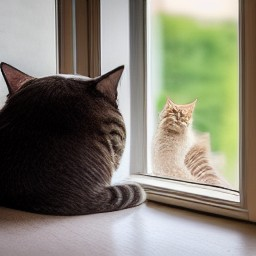

In [1]:
import io
from IPython.display import display, Image as DisplayImage
from PIL import Image
from my_sd15.loader import load_model


def show(*images):
    """画像を横に並べて表示する（ノートブックを軽くするため JPEG にする）"""
    canvas = Image.new("RGB", (sum(im.width for im in images), max(im.height for im in images)))
    x = 0
    for im in images:
        canvas.paste(im, (x, 0))
        x += im.width
    buf = io.BytesIO()
    canvas.save(buf, format="JPEG", quality=90)
    display(DisplayImage(buf.getvalue()))


model = load_model("webui/miniSD")
prompt = "a cat sitting on a windowsill"
image = model.generate(prompt, seed=42)
show(image)

生成はランダムなノイズから始まるため、乱数のシード（`seed`）が変われば、同じプロンプトでも異なる画像になります。逆に、シードを固定すれば同じ画像が再現されます。以下の引数で生成の振る舞いを調整できます。

- **steps**: ノイズを取り除く回数（デフォルト: 10）
- **cfg_scale**: プロンプトに従わせる強さ（デフォルト: 7.5）
- **negative_prompt**: 生成したくない要素

# 推論パイプラインの全体像

SD 1.5 に入力されたテキストは、以下のパイプラインを通って画像になります。

1. テキスト
   - CLIP トークナイザー（BPE）
   - CLIP Text Encoder
2. 条件ベクトル (77, 768)
3. ランダムノイズ (4, 32, 32)
   - デノイジングループ × 10 ステップ
     - U-Net（ノイズを予測）× 2
     - CFG（2 つの予測を合成）
     - DDIM Scheduler（ノイズを一段階除去）
4. 潜在表現 (4, 32, 32)
   - VAE Decoder
5. 画像 (3, 256, 256)

ポイントは、ノイズの除去を 256×256 の画像の上で直接行わないことです。縦横をそれぞれ 1/8 にした 32×32 の**潜在表現**（latents）の上で行い、最後に VAE Decoder で画像に引き伸ばします。小さな下書きを仕上げてから清書する、という分担です。この方式を**潜在拡散**（Latent Diffusion）と呼びます。

GPT-2 と対比すると、ループの回し方が異なります。GPT-2 は 1 回のループでトークンを 1 つ**追加**しますが、SD 1.5 は最初から最後まで同じ形の潜在表現を持ち、ループのたびに全体を**更新**します。

## モデルの重み

重みは safetensors 形式で、コンポーネントごとのファイルに格納されています。主なキーと形状を表示します。

In [2]:
components = [
    ("CLIP Text Encoder", model.text_encoder.state, [
        "text_model.embeddings.token_embedding.weight",
        "text_model.embeddings.position_embedding.weight",
        "text_model.encoder.layers.0.self_attn.q_proj.weight",
    ]),
    ("U-Net", model.unet.state, [
        "conv_in.weight",
        "time_embedding.linear_1.weight",
        "down_blocks.0.resnets.0.conv1.weight",
        "down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_k.weight",
        "conv_out.weight",
    ]),
    ("VAE", model.vae.state, [
        "decoder.conv_in.weight",
        "decoder.conv_out.weight",
    ]),
]
for name, state, keys in components:
    n_params = sum(w.numel() for w in state.values())
    print(f"{name}: {len(state)} テンソル, {n_params:,} パラメーター")
    for key in keys:
        print(f"  {key}: {tuple(state[key].shape)}")

CLIP Text Encoder: 197 テンソル, 123,060,557 パラメーター
  text_model.embeddings.token_embedding.weight: (49408, 768)
  text_model.embeddings.position_embedding.weight: (77, 768)
  text_model.encoder.layers.0.self_attn.q_proj.weight: (768, 768)
U-Net: 686 テンソル, 859,520,964 パラメーター
  conv_in.weight: (320, 4, 3, 3)
  time_embedding.linear_1.weight: (1280, 320)
  down_blocks.0.resnets.0.conv1.weight: (320, 320, 3, 3)
  down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_k.weight: (320, 768)
  conv_out.weight: (4, 320, 3, 3)
VAE: 248 テンソル, 83,653,863 パラメーター
  decoder.conv_in.weight: (512, 4, 3, 3)
  decoder.conv_out.weight: (3, 128, 3, 3)


形状から、次のことが読み取れます。

- CLIP の語彙数は 49408、最大トークン数は 77、埋め込み次元は 768 です。GPT-2 Small（50257、1024、768）とよく似ています。
- U-Net の重みの多くは、`(出力チャネル, 入力チャネル, 3, 3)` という 4 次元の形状です。これは**畳み込み**（Conv2D）の重みで、3×3 の小さな窓（カーネル）を表します。
- `conv_in` は 4 チャネルの潜在表現を 320 チャネルに広げ、`conv_out` は 320 チャネルを 4 チャネルに戻します。U-Net の入力と出力は同じ形状です。
- `attn2.to_k` の形状 (320, 768) は、768 次元のテキスト条件を 320 次元の画像特徴の空間に変換する重みです（Cross-Attention）。
- VAE のファイルには Encoder（画像 → 潜在表現）の重みも含まれますが、画像生成で使うのは Decoder だけです。

## コア推論コード

推論パイプラインの中核は以下のステップに集約されます。

以降のコードを動かすための準備です。先ほど読み込んだ `model` から、各コンポーネントを取り出します。

In [3]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from my_sd15.ops import conv2d, group_norm, linear, silu, softmax
from my_sd15.model import decode_to_image

tokenizer, text_encoder, unet, vae, scheduler = (
    model.tokenizer, model.text_encoder, model.unet, model.vae, model.scheduler)
id_to_token = {i: token for token, i in tokenizer.vocab.items()}

**Step 0: トークナイザー** — テキストをトークン ID の列に変換します。長さは常に 77 に揃えられます。

In [4]:
input_ids = tokenizer.encode(prompt)

print("prompt:", repr(prompt))
print("len(input_ids):", len(input_ids))
print("input_ids[:11]:", [(id_to_token[i], i) for i in input_ids[:11]])

prompt: 'a cat sitting on a windowsill'
len(input_ids): 77
input_ids[:11]: [('<|startoftext|>', 49406), ('a</w>', 320), ('cat</w>', 2368), ('sitting</w>', 4919), ('on</w>', 525), ('a</w>', 320), ('windo', 3110), ('ws', 6300), ('ill</w>', 660), ('<|endoftext|>', 49407), ('<|endoftext|>', 49407)]


**Step 1: CLIP Text Encoder** — トークン ID 列を条件ベクトルに変換します。あとで使うため、空文字列からも条件ベクトル（無条件ベクトル）を作っておきます。

In [5]:
cond_emb = text_encoder(input_ids)               # プロンプトあり
uncond_emb = text_encoder(tokenizer.encode(""))  # プロンプトなし

print("cond_emb.shape:", tuple(cond_emb.shape))
print("uncond_emb.shape:", tuple(uncond_emb.shape))

cond_emb.shape: (77, 768)
uncond_emb.shape: (77, 768)


**Step 2: ランダムノイズ** — 出発点となる潜在表現を、正規乱数（平均 0・標準偏差 1）で作ります。画像の 1/8 の大きさで、チャネルは 4 つです。

In [6]:
generator = torch.manual_seed(42)
latents = torch.randn(4, 256 // 8, 256 // 8, generator=generator)

print("latents.shape:", tuple(latents.shape))
print(f"mean={latents.mean():.4f}, std={latents.std():.4f}")

latents.shape: (4, 32, 32)
mean=-0.0011, std=0.9961


**Step 3: デノイジングループ** — U-Net でノイズを予測し、スケジューラーでその分を取り除くことを 10 回繰り返します。

`t` は**タイムステップ**で、「いまどれくらいノイズが残っているか」を表す目盛りです（999 がほぼ完全なノイズ、0 がノイズなし）。900 から 0 まで、100 刻みで下っていきます。

U-Net は 1 ステップにつき 2 回実行します。プロンプトありの予測と、プロンプトなしの予測の差を `cfg_scale` 倍に広げることで、プロンプトの効き目を強調します（CFG、後述）。

後の節で使うため、各ステップの潜在表現とノイズ予測を記録しておきます。

In [7]:
cfg_scale = 7.5
scheduler.set_timesteps(10)

history = [latents]  # 各ステップの潜在表現（後の節で使用）
noise_preds = []     # 各ステップのノイズ予測（後の節で使用）
x = latents
for t in scheduler.timesteps.tolist():
    noise_cond = unet(x, t, cond_emb)      # プロンプトありのノイズ予測
    noise_uncond = unet(x, t, uncond_emb)  # プロンプトなしのノイズ予測
    noise_pred = noise_uncond + cfg_scale * (noise_cond - noise_uncond)  # CFG
    x = scheduler.step(noise_pred, t, x)   # ノイズを一段階除去
    history.append(x)
    noise_preds.append(noise_pred)
    guidance = (noise_cond - noise_uncond).abs().mean()
    print(f"t={t:3d}: guidance={guidance:.4f}, latents std={x.std():.4f}")

denoised = x

t=900: guidance=0.0072, latents std=0.9912
t=800: guidance=0.0130, latents std=0.9852
t=700: guidance=0.0231, latents std=0.9810
t=600: guidance=0.0165, latents std=0.9684
t=500: guidance=0.0215, latents std=0.9549
t=400: guidance=0.0219, latents std=0.9404
t=300: guidance=0.0229, latents std=0.9241
t=200: guidance=0.0224, latents std=0.9084
t=100: guidance=0.0225, latents std=0.8839
t=  0: guidance=0.0115, latents std=0.8834


**Step 4: VAE Decoder** — 潜在表現を画像に変換します。0.18215 は、潜在表現のスケールを VAE に合わせるための定数です（後述）。

denoised.shape: (4, 32, 32)
decoded.shape: (3, 256, 256)
generate() の結果と一致: True


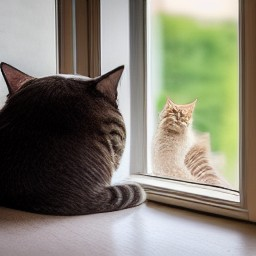

In [8]:
decoded = vae(denoised / 0.18215)
image2 = decode_to_image(decoded)  # 値の範囲 [-1, 1] を [0, 255] に変換

print("denoised.shape:", tuple(denoised.shape))
print("decoded.shape:", tuple(decoded.shape))
print("generate() の結果と一致:", image2.tobytes() == image.tobytes())
show(image2)

以上が、SD 1.5 の推論の全体です。プロンプトをトークン ID に変換し（Step 0）、条件ベクトルにして（Step 1）、ランダムノイズを用意し（Step 2）、U-Net とスケジューラーでノイズを 10 回に分けて取り除き（Step 3）、VAE Decoder で画像にします（Step 4）。同じシードを使ったので、最初に `generate` で生成した画像と完全に一致します。

デノイジングループの出力を見ると、潜在表現の標準偏差は最初から最後まで 1 に近い値のままです。ノイズが画像の情報に置き換わっていくだけで、全体のスケールは大きく変わりません。`guidance` の値は CFG の節で使います。

途中経過を見てみます。ステップ 0（初期ノイズ）、3、6 の時点の潜在表現を VAE Decoder で画像にして、最終結果（ステップ 10）と並べます。

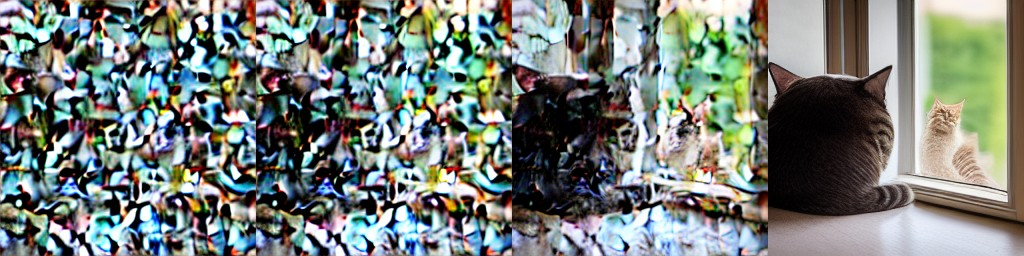

In [9]:
show(*[decode_to_image(vae(history[i] / 0.18215)) for i in (0, 3, 6)], image2)

左から、ステップ 0、3、6、10 です。ステップ 3 まではノイズにしか見えませんが、ステップ 6 では手前の猫に当たる暗い塊が現れ、ステップ 10 で細部まで仕上がります。

なお、途中の潜在表現はノイズを多く含んでいます。VAE Decoder はノイズのない潜在表現を前提にしているため、途中経過を画像にすると、このようなモザイク状の模様になります。

以降の節では、このパイプラインを入力側から順に、各コンポーネントの中身を見ていきます。

# CLIP Text Encoder

CLIP は、画像とテキストを同じベクトル空間に対応付けるよう訓練されたモデルです。画像側とテキスト側の 2 つの Encoder からなり、SD 1.5 はそのうちテキスト側だけを使います。「画像と対応付けて訓練された」ことが重要で、CLIP の出力するベクトルには、テキストが**どんな見た目に対応するか**という情報が含まれています。

## トークナイザー

GPT-2 と同じバイトレベル BPE ですが、次の点が異なります。

| 観点 | GPT-2 | CLIP |
|---|---|---|
| 大文字・小文字 | 区別する | すべて小文字にする |
| 単語境界 | 語頭のスペース（`Ġ`） | 語末の `</w>` |
| 特殊トークン | なし | 先頭に `<\|startoftext\|>`、末尾に `<\|endoftext\|>` |
| 長さ | 可変 | 77 に固定（`<\|endoftext\|>` で埋める） |

In [10]:
print([id_to_token[i] for i in input_ids[:11]])
print("<|endoftext|> の個数:", input_ids.count(tokenizer.eos_token_id))

['<|startoftext|>', 'a</w>', 'cat</w>', 'sitting</w>', 'on</w>', 'a</w>', 'windo', 'ws', 'ill</w>', '<|endoftext|>', '<|endoftext|>']
<|endoftext|> の個数: 68


`windowsill` は語彙にないため、`windo`・`ws`・`ill</w>` の 3 トークンに分かれます。プロンプトは 8 トークンで、先頭の `<|startoftext|>` と合わせて 9 個、残りの 68 個はすべて `<|endoftext|>` です。

## Transformer

CLIP Text Encoder の中身は、GPT-2 とほぼ同じ 12 層の Transformer です。

| 観点 | GPT-2 Small | CLIP Text Encoder |
|---|---|---|
| 層数・ヘッド数・次元 | 12・12・768 | 12・12・768 |
| 因果マスク | あり | あり |
| 活性化関数 | GELU | Quick GELU（`x * sigmoid(1.702 * x)`） |
| 出力 | 最後のトークンから次のトークンを予測 | 77 個のベクトルをすべて条件として使用 |

最大の違いは出力の使い方です。GPT-2 は最後の位置のベクトルだけを使いましたが、SD 1.5 は LM Head を通さず、最終 LayerNorm 後の 77 個のベクトルをそのまま U-Net に渡します。

因果マスクがあるので、各位置のベクトルは自分より前のトークンの情報しか含みません。プロンプトありの `cond_emb` と、プロンプトなしの `uncond_emb` を位置ごとに比べて確かめます。

In [11]:
diff = (cond_emb - uncond_emb).abs().mean(dim=-1)  # 位置ごとの平均絶対差
for i in (0, 1, 2, 8, 9, 76):
    print(f"位置 {i:2d} {id_to_token[input_ids[i]]:16s} {diff[i]:.4f}")

位置  0 <|startoftext|>  0.0000
位置  1 a</w>            0.9062
位置  2 cat</w>          1.0218
位置  8 ill</w>          1.0354
位置  9 <|endoftext|>    0.9694
位置 76 <|endoftext|>    0.9260


位置 0 の差は 0 です。先頭の `<|startoftext|>` は自分自身しか参照できないので、後ろに何が続いても同じベクトルになります。位置 1 以降は、プロンプトの有無で異なるベクトルになります。

位置 9 以降は、どちらも同じ `<|endoftext|>` トークンですが、ベクトルは異なります。前にあるプロンプト全体を参照できるためです。埋め草に見える `<|endoftext|>` の位置にも、プロンプトの情報が入っています。

# Conv2D（畳み込み）

ここからは U-Net の部品を見ていきます。最初は、画像を扱うための基本演算である**畳み込み**です。GPT-2 の Linear（全結合）に相当する役割を、画像に対して担います。

画像では、近くにあるピクセル同士が強く関係します。また、「縁」や「毛並み」のような模様は、画像のどこに現れても同じ模様です。そこで畳み込みは、3×3 などの小さな窓（**カーネル**）を画像の上で滑らせ、各位置で「窓の中の値」と「カーネルの重み」の内積を計算します。内積は、窓の中がカーネルの模様に似ているほど大きくなるので、カーネルは「探したい模様」と読めます。

同じカーネルを全位置で使い回すので、パラメーター数は画像の大きさによりません。

実装では、窓を滑らせるループを行列積に置き換えます。すべての窓の中身をあらかじめ列として並べた行列（`col`）を作っておけば、カーネルとの内積は 1 回の行列積で済みます。この方法を **im2col** と呼びます。3×3 の入力と 2×2 のカーネルで確かめます。

In [12]:
toy_x = torch.tensor([[[1., 2., 0.],
                       [0., 1., 3.],
                       [2., 0., 1.]]])  # (C_in=1, H=3, W=3)
toy_w = torch.tensor([[[[1., 0.],
                        [0., 1.]]]])    # (C_out=1, C_in=1, kH=2, kW=2): 対角の 2 つを足す

# im2col: 2×2 の窓を 1 つずつずらして切り出し、窓の中身を列として並べる
col = toy_x.unfold(1, 2, 1).unfold(2, 2, 1)       # (C_in, H_out, W_out, kH, kW)
col = col.permute(0, 3, 4, 1, 2).reshape(4, 4)    # (C_in*kH*kW, H_out*W_out)
kernel = toy_w.reshape(1, -1)                     # (C_out, C_in*kH*kW)
toy_out = (kernel @ col).reshape(1, 2, 2)         # 全位置の内積を 1 回の行列積で計算

print("col（列が 1 つの窓に対応）:")
print(col)
print("kernel:", kernel)
print("出力:")
print(toy_out)

col（列が 1 つの窓に対応）:
tensor([[1., 2., 0., 1.],
        [2., 0., 1., 3.],
        [0., 1., 2., 0.],
        [1., 3., 0., 1.]])
kernel: tensor([[1., 0., 0., 1.]])
出力:
tensor([[[2., 5.],
         [0., 2.]]])


`col` の各列が 1 つの窓の中身です。例えば左上の窓 `[[1, 2], [0, 1]]` は、1 列目の `[1, 2, 0, 1]` になります。カーネル `[1, 0, 0, 1]` との内積は 1 + 1 = 2 で、出力の左上の値になります。4 つの窓すべてについて、この内積が 1 回の行列積で計算されています。

実際の重みでも確かめます。U-Net の入口にある `conv_in` は、4 チャネルの潜在表現を 320 チャネルに広げます。入力の周囲を 0 で 1 マス分埋める（`padding=1`）ので、縦横の大きさは変わりません。出力の各チャネルは、それぞれ別の模様に対する反応の強さを表す**特徴マップ**です。

In [13]:
conv_in_w, conv_in_b = unet.state["conv_in.weight"], unet.state["conv_in.bias"]
features = conv2d(latents, conv_in_w, conv_in_b, padding=1)

# 確認: PyTorch の F.conv2d と同じ結果になる
reference = F.conv2d(latents[None], conv_in_w, conv_in_b, padding=1)[0]
print(tuple(latents.shape), "→", tuple(features.shape))
print("F.conv2d との最大誤差:", (features - reference).abs().max().item())

(4, 32, 32) → (320, 32, 32)
F.conv2d との最大誤差: 0.0


# GroupNorm

GPT-2 の LayerNorm は、トークンごとに 768 個の値を平均 0・分散 1 に正規化しました。U-Net では代わりに **GroupNorm** を使います。チャネルをいくつかのグループに分け、グループごとに、空間方向も含めたすべての値をまとめて正規化します。

SD 1.5 のグループ数は 32 です。320 チャネルなら 10 チャネルずつのグループになり、32×32 の特徴マップでは 1 グループあたり 10 × 32 × 32 = 10,240 個の値が正規化の単位になります。

正規化の後に、チャネルごとの学習済みパラメーター γ（スケール）と β（シフト）を適用するのは LayerNorm と同じです。先ほどの `conv_in` の出力を、U-Net の最初のブロックにある GroupNorm に通します。

In [14]:
gamma = unet.state["down_blocks.0.resnets.0.norm1.weight"]  # (320,)
beta = unet.state["down_blocks.0.resnets.0.norm1.bias"]     # (320,)

# group_norm(features, gamma, beta, 32) と同じ計算
grouped = features.reshape(32, -1)                          # (32 グループ, 10240 個)
mean = grouped.mean(dim=1, keepdim=True)                    # グループごとの平均
var = grouped.var(dim=1, unbiased=False, keepdim=True)      # グループごとの分散
grouped_norm = (grouped - mean) / torch.sqrt(var + 1e-5)    # 正規化
normed = grouped_norm.reshape(features.shape) * gamma.reshape(-1, 1, 1) + beta.reshape(-1, 1, 1)

# 確認: 最初の 4 グループの (平均, 分散)
torch.set_printoptions(precision=3, sci_mode=False)
print("入力 (平均, 分散):")
print(torch.cat([mean, var], dim=1)[:4])
print("正規化後 (平均, 分散):")
print(torch.stack([grouped_norm.mean(dim=1), grouped_norm.var(dim=1, unbiased=False)], dim=1)[:4])
print("group_norm() と一致:", torch.allclose(normed, group_norm(features, gamma, beta, 32), atol=1e-5))

入力 (平均, 分散):
tensor([[-0.007,  0.163],
        [-0.002,  0.132],
        [ 0.002,  0.105],
        [ 0.023,  0.159]])
正規化後 (平均, 分散):
tensor([[-0.000,  1.000],
        [ 0.000,  1.000],
        [-0.000,  1.000],
        [ 0.000,  1.000]])
group_norm() と一致: True


グループごとにばらばらだった平均と分散が、正規化によって 0 と 1 に揃います。

LayerNorm のように全チャネルをまとめて正規化すると、チャネルごとの特徴の強弱が均されてしまいます。逆にチャネルごとに正規化すると、値の数が少なく不安定になります。GroupNorm はその中間で、グループ数がその度合いを決めるつまみになっています。

# U-Net

U-Net は、SD 1.5 のパラメーターの約 8 割を占める中心的なネットワークです。ノイズ混じりの潜在表現を受け取り、**その中のどこがノイズか**を、同じ形状のテンソルとして予測します。

入力は 3 つあり、それぞれ別の経路で注入されます。

| 入力 | 形状 | 注入する場所 |
|---|---|---|
| 潜在表現 | (4, 32, 32) | 入口の `conv_in` |
| タイムステップ | 整数 | 各 ResBlock |
| 条件ベクトル | (77, 768) | 各 SpatialTransformer の Cross-Attention |

名前の由来は、処理の流れが U 字型になることです。前半で空間を縮小しながらチャネルを増やし、後半で空間を拡大しながらチャネルを減らします。ST は SpatialTransformer の略です。図中の SiLU は活性化関数で、後述します。

```text
latents (4, 32, 32)
  ↓ conv_in
(320, 32, 32)   Down 0: [ResBlock, ST] × 2 → 縮小 ─────────┐ スキップ接続
(640, 16, 16)   Down 1: [ResBlock, ST] × 2 → 縮小 ───────┐ │
(1280, 8, 8)    Down 2: [ResBlock, ST] × 2 → 縮小 ─────┐ │ │
(1280, 4, 4)    Down 3: [ResBlock] × 2 ──────────────┐ │ │ │
(1280, 4, 4)    Mid:    ResBlock, ST, ResBlock       │ │ │ │
(1280, 4, 4)    Up 0:   [結合, ResBlock] × 3 → 拡大 ←┘ │ │ │
(1280, 8, 8)    Up 1:   [結合, ResBlock, ST] × 3 → 拡大 ←┘ │ │
(640, 16, 16)   Up 2:   [結合, ResBlock, ST] × 3 → 拡大 ←──┘ │
(320, 32, 32)   Up 3:   [結合, ResBlock, ST] × 3 ←───────────┘
  ↓ GroupNorm → SiLU → conv_out
noise_pred (4, 32, 32)
```

空間を縮小すると、3×3 のカーネルでも元の画像の広い範囲を見渡せるようになり、「猫が窓辺にいる」といった全体の構図を扱いやすくなります。一方、縮小すると細部の位置の情報は失われます。そこで、縮小前の特徴を保存しておき、拡大する側で同じ解像度の特徴に**結合**（`torch.cat`）して渡します。これが**スキップ接続**で、全部で 12 本あります。

以降では、U-Net を構成する ResBlock と SpatialTransformer の中身を見ていきます。

## タイムステップ埋め込み

U-Net は、ノイズだらけの序盤では大まかな構図を、ノイズの少ない終盤では細部を決める必要があります。同じ重みで振る舞いを切り替えるため、いまのタイムステップを U-Net に伝えます。

整数のタイムステップは、周波数の異なる 160 組の cos・sin で 320 次元のベクトルに変換します。時計が、速さの異なる複数の針の組み合わせで時刻を表すのと同じ考え方です。GPT-2 の位置埋め込み（WPE）は学習済みの表でしたが、こちらは計算式で作ります。

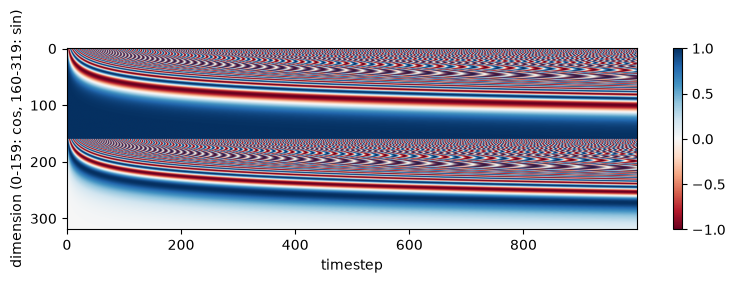

In [15]:
def sinusoidal(timestep):
    half = 160
    freqs = torch.exp(-math.log(10000) * torch.arange(half) / half)  # 1 から 1/10000 へ下がる周波数
    args = timestep * freqs
    return torch.cat([torch.cos(args), torch.sin(args)])             # (320,)

table = torch.stack([sinusoidal(t) for t in range(1000)])            # (1000, 320)

plt.figure(figsize=(8, 2.6))
plt.imshow(table.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
plt.xlabel("timestep")
plt.ylabel("dimension (0-159: cos, 160-319: sin)")
plt.colorbar()
plt.tight_layout()
plt.show()

横軸がタイムステップ、縦軸がベクトルの次元です。上半分が cos、下半分が sin で、それぞれ上の次元ほど周波数が高く、細かく振動します。縦に 1 列切り出したものが、そのタイムステップを表す 320 次元のベクトルです。周波数の高い次元は近いタイムステップ同士の区別に、低い次元は大まかな位置の区別に役立ちます。

このベクトルを、2 層の MLP（Linear → SiLU → Linear）で 1280 次元に変換したものが、タイムステップ埋め込み `temb` です。**SiLU** は `x * sigmoid(x)` で定義される活性化関数で、U-Net と VAE で使われます。

In [16]:
s = unet.state
temb = linear(sinusoidal(900), s["time_embedding.linear_1.weight"], s["time_embedding.linear_1.bias"])
temb = silu(temb)
temb = linear(temb, s["time_embedding.linear_2.weight"], s["time_embedding.linear_2.bias"])

print("temb.shape:", tuple(temb.shape))
print("U-Net 内部の計算と一致:", torch.allclose(temb, unet._timestep_embedding(900), atol=1e-5))

temb.shape: (1280,)
U-Net 内部の計算と一致: True


## ResBlock

ResBlock は、「GroupNorm → SiLU → Conv」を 2 回重ね、その結果を入力に加算する（残差接続）ブロックです。GPT-2 の Transformer Block と同じく、ブロックの中身は入力に対する「修正量」を計算します。

```text
Input──────┐
  │        ↓
  │  GroupNorm → SiLU → Conv
  │        ↓
  │       (+)← temb（Linear でチャネル数に変換）
  │        ↓
  │  GroupNorm → SiLU → Conv
  ↓        │
 (+)←──────┘ 残差接続
  ↓
Output
```

タイムステップ埋め込みは、2 つの Conv の間で加算します。チャネルごとに 1 つの値を、全ピクセルに一律に足します。「このタイムステップでは、この特徴を強める・弱める」という調整です。

最初の ResBlock（`down_blocks.0.resnets.0`）を、`conv_in` の出力 `features` に対して計算します。

In [17]:
from my_sd15.unet import UNetResBlock

p = "down_blocks.0.resnets.0."
h = silu(group_norm(features, s[p + "norm1.weight"], s[p + "norm1.bias"], 32))
h = conv2d(h, s[p + "conv1.weight"], s[p + "conv1.bias"], padding=1)
t_proj = linear(silu(temb), s[p + "time_emb_proj.weight"], s[p + "time_emb_proj.bias"])  # (1280,) → (320,)
h = h + t_proj.reshape(-1, 1, 1)                    # チャネルごとに、全ピクセルへ加算
h = silu(group_norm(h, s[p + "norm2.weight"], s[p + "norm2.bias"], 32))
h = conv2d(h, s[p + "conv2.weight"], s[p + "conv2.bias"], padding=1)
res_out = features + h                              # 残差接続

# 確認
print("入力:", tuple(features.shape), "→ 出力:", tuple(res_out.shape))
print(f"入力の大きさ: {features.abs().mean():.4f}, 修正量の大きさ: {h.abs().mean():.4f}")
print("UNetResBlock と一致:", torch.allclose(res_out, UNetResBlock(s, p, 320, 320)(features, temb), atol=1e-4))

入力: (320, 32, 32) → 出力: (320, 32, 32)
入力の大きさ: 0.3024, 修正量の大きさ: 0.3646
UNetResBlock と一致: True


入力と出力でチャネル数が変わる ResBlock では、そのままでは加算できないため、入力側を 1×1 の畳み込み（`conv_shortcut`）でチャネル数だけ変換してから加算します。

## SpatialTransformer

SpatialTransformer は、画像の特徴マップに Transformer を適用するブロックです。特徴マップ (C, H, W) を、ピクセルを 1 トークンとみなした系列 (H×W, C) に並べ替えて、次の 3 つを順に適用します。いずれも LayerNorm と残差接続を伴います。

1. **Self-Attention**: ピクセル同士が互いを参照します。畳み込みでは届かない、離れた位置同士の関係を扱います。
2. **Cross-Attention**: ピクセルがテキストのトークンを参照します。プロンプトの内容が画像に注入される場所です。
3. **GEGLU**: GPT-2 の MLP に当たります。中間の出力を 2 つに分け、一方を GELU に通して、もう一方に掛ける「ゲート」として使います。

GPT-2 と違って因果マスクはありません。画像には生成の順序がなく、すべてのピクセルが互いを参照できます。

Attention の計算量は系列長の 2 乗に比例します。32×32 の特徴マップでも系列長は 1024 になり、GPT-2 の最大トークン列長と同じです。256×256 の画像の上で直接計算するのが現実的でないことが分かります。

## Cross-Attention

Cross-Attention の計算は Self-Attention と同じですが、Q と K・V を**別の系列**から作ります。

- **Q**: 画像の各ピクセルから作ります。「この場所には何を描くべきか」という問い合わせです。
- **K・V**: テキストの各トークンから作ります。K は「自分はこういう内容だ」という名乗り、V は実際に渡す情報です。

Q と K の内積を Softmax に通した注目度は (ピクセル数, 77) の形になり、「どのピクセルが、どのトークンにどれだけ注目しているか」を表します。

### Encoder-Decoder との関係

Cross-Attention は、もともと Transformer の原論文で、Decoder が Encoder の出力を参照するための仕組みです。GPT-2 は Decoder だけのモデルなので、Cross-Attention はありませんでした。SD 1.5 では、CLIP Text Encoder が Encoder、U-Net が Decoder の役割を担っていると読めます。

| | 原論文の Transformer（翻訳） | SD 1.5 |
|---|---|---|
| 参照される側（K・V を出す） | Encoder: 原文を読む | CLIP Text Encoder: プロンプトを読む |
| 参照する側（Q を出す） | Decoder: 訳文を生成する | U-Net: ノイズを予測する |

参照される側は最初に 1 回だけ実行され、参照する側がその出力を繰り返し読みに行く、という使い方も共通しています。ただし、原論文の Encoder-Decoder と同じものではありません。

- U-Net は Transformer ではなく、畳み込みが主体です。自己回帰もせず、マスクなしで全ピクセルを同時に更新します。
- CLIP Text Encoder には因果マスクがあります。原論文の Encoder は前後の両方向を参照するので、名前は Encoder でも、中身は GPT-2 と同じ Decoder 型の構造です。
- 2 つは別々に学習されました。SD 1.5 では学習済みの CLIP を固定して使い、U-Net だけが拡散の学習を受けています。

なお、U-Net の前半（縮小する側）と後半（拡大する側）や、VAE の Encoder と Decoder も同じ名前で呼ばれますが、これらは Cross-Attention とは関係のない、別の意味の組です。

実際の計算を追うには、U-Net の途中にある Cross-Attention への入力が必要です。入力を記録するように `CrossAttention` の呼び出しを一時的に差し替えて、U-Net を 1 回実行します。入力には、デノイジングループの中間（ステップ 5、t=400）の潜在表現を使います。

In [18]:
from my_sd15.unet import CrossAttention

captured = {}
original_call = CrossAttention.__call__

def recording_call(self, x, context=None):
    if context is not None:  # Cross-Attention のときだけ入力を記録
        captured[self.prefix] = x
    return original_call(self, x, context)

CrossAttention.__call__ = recording_call
unet(history[5], scheduler.timesteps[5].item(), cond_emb)
CrossAttention.__call__ = original_call  # 元に戻す

print("記録した Cross-Attention の数:", len(captured))

記録した Cross-Attention の数: 16


解像度 16×16 の層（`up_blocks.2.attentions.1`）を例に、Cross-Attention を計算します。ヘッド数は 8 です。

In [19]:
p = "up_blocks.2.attentions.1.transformer_blocks.0.attn2."
x = captured[p]                       # 画像の特徴 (256, 640)

q = x @ s[p + "to_q.weight"].T        # 画像から Q    (256, 640)
k = cond_emb @ s[p + "to_k.weight"].T # テキストから K (77, 768) → (77, 640)
v = cond_emb @ s[p + "to_v.weight"].T # テキストから V (77, 768) → (77, 640)

# 8 ヘッドに分割: (系列長, 640) → (8, 系列長, 80)
q = q.reshape(256, 8, 80).permute(1, 0, 2)
k = k.reshape(77, 8, 80).permute(1, 0, 2)
v = v.reshape(77, 8, 80).permute(1, 0, 2)

attn = softmax(q @ k.transpose(-2, -1) / 80 ** 0.5)     # 注目度 (8, 256, 77)
out = (attn @ v).permute(1, 0, 2).reshape(256, 640)     # V の重み付き平均
out = linear(out, s[p + "to_out.0.weight"], s[p + "to_out.0.bias"])  # 出力射影

# 確認
print("x:", tuple(x.shape), " attn:", tuple(attn.shape), " out:", tuple(out.shape))
print("CrossAttention と一致:", torch.allclose(out, CrossAttention(s, p, 640)(x, cond_emb), atol=1e-4))

x: (256, 640)  attn: (8, 256, 77)  out: (256, 640)
CrossAttention と一致: True


注目度を 8 ヘッドで平均し、トークンごとに 16×16 の画像として描きます。`windowsill` は 3 トークンの合計です。左端は比較のための最終結果です。

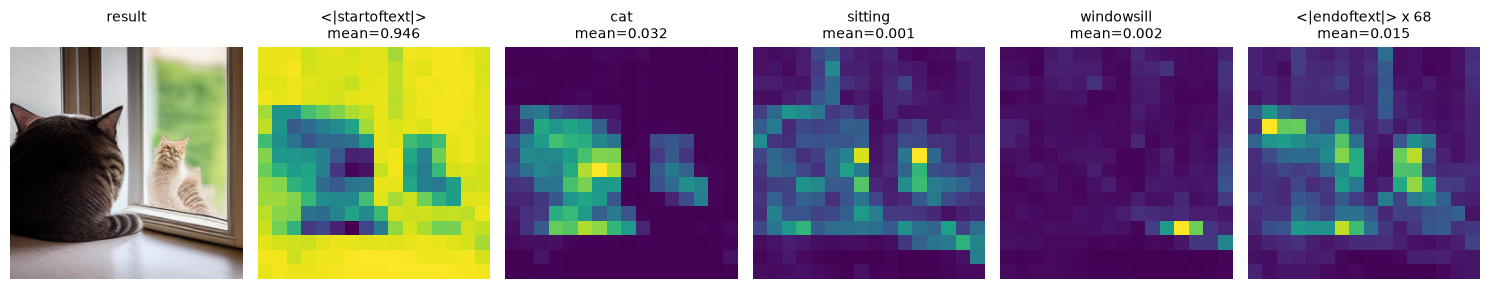

In [20]:
attn_mean = attn.mean(dim=0)  # ヘッドの平均 (256, 77)
maps = [
    ("<|startoftext|>", attn_mean[:, 0]),
    ("cat", attn_mean[:, 2]),
    ("sitting", attn_mean[:, 3]),
    ("windowsill", attn_mean[:, 6:9].sum(dim=1)),
    ("<|endoftext|> x 68", attn_mean[:, 9:].sum(dim=1)),
]

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(image2)
axes[0].set_title("result\n", fontsize=10)
for ax, (title, m) in zip(axes[1:], maps):
    ax.imshow(m.reshape(16, 16))
    ax.set_title(f"{title}\nmean={m.mean():.3f}", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

`cat` の注目度は、手前の猫と窓の外の猫の両方の領域で高くなっています。プロンプトの `cat` という単語が、画像のどこに猫を描くかと結び付いていることが分かります。`windowsill` は、右下の窓台の辺りに強い反応があります。

タイトルの `mean` は、そのトークンへの注目度を全ピクセルで平均したものです。注目度の大半（約 95 %）は先頭の `<|startoftext|>` に集まっています。このトークンのベクトルはプロンプトによらず一定（CLIP の節で確認）なので、プロンプトの情報を運ぶのは残りの約 5 % です。`<|startoftext|>` への注目度が猫の領域で低くなっているのは、その分がプロンプトのトークンに向けられているためです。

この層・このタイムステップでの一例であり、ほかの層やヘッドでは異なる注目の仕方をします。

# DDIM Scheduler

U-Net が予測するのは「どこがノイズか」だけです。その予測を使って潜在表現を実際に更新するのが**スケジューラー**の役割で、SD 1.5 では DDIM という方式がよく使われます。スケジューラーには学習済みの重みがなく、計算式だけでできています。

## ノイズの混ぜ方

拡散モデルの学習では、きれいな画像の潜在表現 $x_0$ にノイズ $\epsilon$ を混ぜたもの $x_t$ を作り、U-Net に「混ぜたノイズを当てさせる」ことを繰り返します。混ぜ方は次の式で決まっています。

$$x_t = \sqrt{\bar\alpha_t}\ x_0 + \sqrt{1 - \bar\alpha_t}\ \epsilon$$

$\sqrt{\bar\alpha_t}$ は画像（信号）の割合、$\sqrt{1 - \bar\alpha_t}$ はノイズの割合で、タイムステップ $t$ ごとに値が決まっています。2 つの係数をグラフにします。点は、10 ステップで使うタイムステップ（900, 800, ..., 0）です。

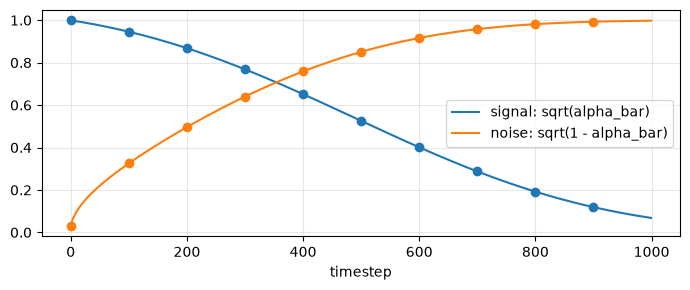

t=999: 信号 0.0683, ノイズ 0.9977
t=900: 信号 0.1190, ノイズ 0.9929
t=500: 信号 0.5257, ノイズ 0.8507
t=100: 信号 0.9456, ノイズ 0.3252
t=  0: 信号 0.9996, ノイズ 0.0292


In [21]:
alphas_cumprod = scheduler.alphas_cumprod      # (1000,)
signal = torch.sqrt(alphas_cumprod)            # 信号の係数
noise = torch.sqrt(1 - alphas_cumprod)         # ノイズの係数
ts = scheduler.timesteps

plt.figure(figsize=(7, 3))
plt.plot(signal, label="signal: sqrt(alpha_bar)")
plt.plot(noise, label="noise: sqrt(1 - alpha_bar)")
plt.plot(ts, signal[ts], "o", color="C0")
plt.plot(ts, noise[ts], "o", color="C1")
plt.xlabel("timestep")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for t in (999, 900, 500, 100, 0):
    print(f"t={t:3d}: 信号 {signal[t]:.4f}, ノイズ {noise[t]:.4f}")

タイムステップが大きいほどノイズの割合が高く、t=999 ではほぼ完全なノイズ、t=0 ではほぼ元の画像になります。推論は、この坂を右から左へ下る操作です。

## DDIM の 1 ステップ

推論では $x_t$ と、U-Net によるノイズの予測 $\epsilon$ が手元にあります。DDIM の 1 ステップは、次の 2 つの手順からなります。

1. **ノイズのない画像を見積もる**: 混ぜ方の式を $x_0$ について解きます。
2. **1 つ先のタイムステップまで戻す**: 見積もった $x_0$ に、同じ $\epsilon$ を、1 つ先のタイムステップ $t'$ の割合で混ぜ直します。

$$\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar\alpha_t}\ \epsilon}{\sqrt{\bar\alpha_t}}, \qquad x_{t'} = \sqrt{\bar\alpha_{t'}}\ \hat{x}_0 + \sqrt{1 - \bar\alpha_{t'}}\ \epsilon$$

デノイジングループの最初のステップ（t=900 → 800）を、記録しておいた潜在表現とノイズ予測から計算し直します。

In [22]:
t, t_prev = 900, 800
x_t, eps = history[0], noise_preds[0]

pred_x0 = (x_t - noise[t] * eps) / signal[t]         # 手順 1: ノイズのない画像を見積もる
x_prev = signal[t_prev] * pred_x0 + noise[t_prev] * eps  # 手順 2: t=800 のノイズ量に混ぜ直す

# 確認
print("scheduler.step() の結果と一致:", torch.allclose(x_prev, history[1], atol=1e-5))
print(f"pred_x0 の std: {pred_x0.std():.4f}, x_prev の std: {x_prev.std():.4f}")

scheduler.step() の結果と一致: True
pred_x0 の std: 0.6339, x_prev の std: 0.9912


手順 1 で $x_0$ が見積もれるなら、なぜ 1 回で終わりにしないのでしょうか。ステップ 0（t=900）とステップ 5（t=400）の時点で見積もった $\hat{x}_0$ を画像にして、最終結果と並べます。

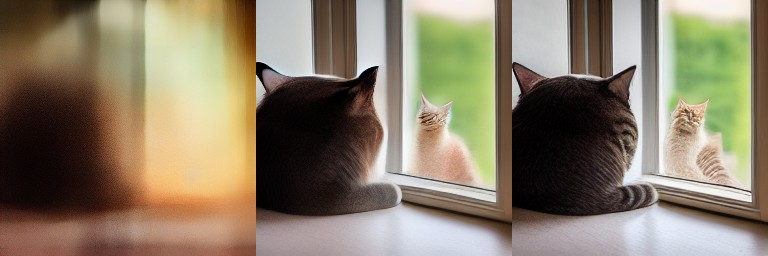

In [23]:
def estimate_x0(i):
    t = scheduler.timesteps[i]
    return (history[i] - noise[t] * noise_preds[i]) / signal[t]

show(*[decode_to_image(vae(estimate_x0(i) / 0.18215)) for i in (0, 5)], image2)

左から、ステップ 0（t=900）での見積もり、ステップ 5（t=400）での見積もり、最終結果です。

t=900 では信号の係数が約 0.12 しかなく、入力のほとんどがノイズです。この段階の見積もりは、左下が暗く右側が明るいといった大まかな配置だけを含む、ぼやけたものになります。1 回で終わりにすると、この画像が結果になってしまいます。

t=400 での見積もりは最終結果にかなり近づいていますが、猫の耳や縞模様など、細部はまだ異なります。DDIM は、粗い見積もりを信じ切らず、ノイズを少しだけ減らした状態に戻して U-Net にもう一度予測させることを繰り返します。ノイズが減るほど見積もりは正確になるので、階段を一段ずつ降りるように、構図から細部へと順に決まっていきます。

# VAE Decoder

VAE（Variational Autoencoder）は、画像を小さな潜在表現に圧縮する Encoder と、潜在表現から画像を復元する Decoder の組です。画像生成では Decoder だけを使います。

256×256 の RGB 画像は 3 × 256 × 256 = 196,608 個の値ですが、潜在表現は 4 × 32 × 32 = 4,096 個で、48 分の 1 です。画像には、隣り合うピクセルがほぼ同じ色になるといった冗長性が多いため、ここまで圧縮しても見た目をほぼ復元できます。潜在表現の 1 マスは、画像の 8×8 ピクセルの範囲に対応します。

Decoder の構造は、U-Net の後半（拡大する側）に似ています。ResBlock を重ねながら 3 回の拡大で 32 → 64 → 128 → 256 と広げ、チャネルは 512 → 256 → 128 と減らして、最後に 3 チャネル（RGB）にします。タイムステップも条件ベクトルも受け取りません。

潜在表現の 4 つのチャネルを、そのまま画像として描いてみます。

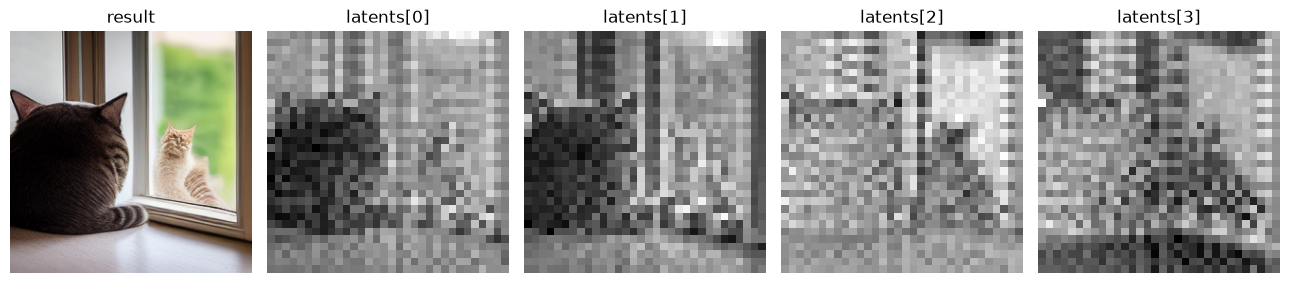

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(13, 2.8))
axes[0].imshow(image2)
axes[0].set_title("result")
for i, ax in enumerate(axes[1:]):
    ax.imshow(denoised[i], cmap="gray")
    ax.set_title(f"latents[{i}]")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

32×32 と粗いものの、どのチャネルにも猫の輪郭や窓枠が読み取れます。潜在表現は、意味の分からない数値の並びではなく、画像を縮小したような空間的な配置を保っています。U-Net が潜在表現に対して畳み込みを使えるのは、このためです。

## スケーリング係数

VAE Encoder が出力する潜在表現は、標準偏差が 1 よりかなり大きくなります。一方、拡散の計算は標準偏差 1 のノイズを基準にしています。そこで、学習時に潜在表現へ 0.18215 を掛けて、スケールをおよそ 1 に揃えています。Decoder に渡すときは、逆に 0.18215 で割って元のスケールに戻します。

In [25]:
print(f"denoised の std: {denoised.std():.4f}")
print(f"denoised / 0.18215 の std: {(denoised / 0.18215).std():.4f}")
print(f"decoded の範囲: {decoded.min():.4f} 〜 {decoded.max():.4f}")

denoised の std: 0.8834
denoised / 0.18215 の std: 4.8498
decoded の範囲: -1.0662 〜 1.0697


Decoder の出力はおよそ -1〜1 の範囲で、`decode_to_image` がこれを 0〜255 に変換して画像にします。

# CFG（Classifier-Free Guidance）

デノイジングループでは、U-Net を 2 回実行して、結果を次の式で合成しました。$s$ は `cfg_scale` です。

$$\epsilon = \epsilon_{uncond} + s \cdot (\epsilon_{cond} - \epsilon_{uncond})$$

2 つの予測の違いはプロンプトの有無だけなので、差分 $\epsilon_{cond} - \epsilon_{uncond}$ は**プロンプトの効き目だけを取り出したもの**と言えます。CFG は、プロンプトなしの予測を出発点として、この差分の方向へ $s$ 倍だけ進みます。

```text
ε_uncond        ε_cond                              ε
   ●─────────────→●─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─ ─→●
   │← 差分（s=1）→│
   │←────────── 差分を s 倍に延長（s=7.5）────────→│
```

プロンプトありの予測で止まらず、同じ方向にさらに行き過ぎるのがポイントです。似顔絵で特徴を誇張するのに似ています。

デノイジングループの出力で `guidance` として表示した値が、この差分の大きさ（平均絶対値）です。U-Net が予測するノイズは標準偏差がほぼ 1 なので、プロンプトの有無による違いはその 1〜2 % 程度にすぎません。この小さな差を増幅しないと、プロンプトが十分に反映されません。

$s = 1$ のときは式全体が $\epsilon_{cond}$ になり、増幅なしになります。`cfg_scale=1.0` で生成した画像（左）を、7.5 の画像（右）と比べます。

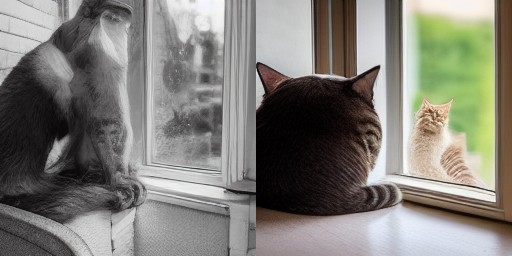

In [26]:
image_cfg1 = model.generate(prompt, seed=42, cfg_scale=1.0)
show(image_cfg1, image)

`cfg_scale=1.0` の画像は、窓辺に動物がいるという構図にはなっていますが、色が乏しく、猫とは言いにくい姿です。プロンプトの効き目を増幅することで、内容がはっきり現れた画像になります。ただし、増幅しすぎるとコントラストが強すぎる不自然な画像になります。

GPT-2 の temperature が「確率分布の鋭さ」を調整したのに対し、CFG は「条件付けの強さ」を調整します。

**Negative Prompt** は、プロンプトなしの側（`uncond_emb`）に、空文字列の代わりにテキストを入れたものです。出発点が「何もなし」から「避けたい内容」に置き換わるので、プロンプトに近づくと同時に、Negative Prompt の内容から遠ざかる効果が生まれます。特別な仕組みではなく、CFG の式をそのまま使っています。

# LoRA と LCM

最後に、学習済みのモデルを少量のパラメーターで修正する **LoRA**（Low-Rank Adaptation）と、その応用で生成を高速化する **LCM LoRA** を扱います。

## LoRA

モデルの振る舞いを変えるには重み $W$ を更新すればよいのですが、U-Net 全体では 8.6 億個もあります。LoRA は、$W$ そのものではなく、差分 $\Delta W$ を 2 つの細長い行列の積として持ちます。

$$W' = W + \frac{\alpha}{r}\ B A$$

$A$ は ($r$, 入力次元)、$B$ は (出力次元, $r$) の行列で、$r$ を**ランク**と呼びます。$r$ が小さければ、パラメーター数は $W$ よりずっと少なくなります。ランク 1 の小さな例で確かめます。

In [27]:
toy_b = torch.tensor([[1.], [2.]])     # (出力 2, r=1)
toy_a = torch.tensor([[1., 0., 3.]])   # (r=1, 入力 3)
print(toy_b @ toy_a)                   # (2, 3) の差分を、2 + 3 = 5 個の値で表す

tensor([[1., 0., 3.],
        [2., 0., 6.]])


6 個の値を持つ行列が、5 個の値から作られます。ただし、どの行も `[1, 0, 3]` の定数倍で、自由に 6 個の値を決められるわけではありません。$A$ は「入力のどの方向を読むか」、$B$ は「それを出力のどの方向に書き込むか」を表し、ランク $r$ はその組の数です。表現できる差分は限られますが、学習済みモデルの微調整にはそれで足りることが多い、というのが LoRA の考え方です。

実際の LoRA ファイル（後述の LCM LoRA）を読み、Cross-Attention の `to_k` に対する差分を計算します。

In [28]:
from safetensors import safe_open
from my_sd15.loader import resolve_lora_path

lora_path = resolve_lora_path("latent-consistency/lcm-lora-sdv1-5")
model_key = "down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_k.weight"
lora_key = "lora_unet_down_blocks_0_attentions_0_transformer_blocks_0_attn2_to_k"
with safe_open(lora_path, framework="pt") as f:
    n_targets = sum(key.endswith(".alpha") for key in f.keys())
    lora_a = f.get_tensor(lora_key + ".lora_down.weight").float()  # A
    lora_b = f.get_tensor(lora_key + ".lora_up.weight").float()    # B
    alpha = f.get_tensor(lora_key + ".alpha").item()

w = unet.state[model_key]
rank = lora_a.shape[0]
delta = (alpha / rank) * lora_b @ lora_a

print("LoRA の適用対象:", n_targets, "個の重み")
print("W:", tuple(w.shape), " A:", tuple(lora_a.shape), " B:", tuple(lora_b.shape))
print(f"r={rank}, alpha={alpha}, alpha/r={alpha / rank}")
print(f"パラメーター数: W {w.numel():,}, A + B {lora_a.numel() + lora_b.numel():,}")
print(f"大きさ（ノルム）: W {w.norm():.4f}, 差分 {delta.norm():.4f}")

LoRA の適用対象: 278 個の重み
W: (320, 768)  A: (64, 768)  B: (320, 64)
r=64, alpha=8.0, alpha/r=0.125
パラメーター数: W 245,760, A + B 69,632
大きさ（ノルム）: W 28.2482, 差分 0.0522


この LoRA は、U-Net の 278 個の重みに対して、それぞれ $A$ と $B$ の組を持っています。ランクは 64 で、`to_k` の場合は元の重みの 3 割弱のパラメーター数で差分を表しています。チャネル数の多い層ほど、この割合は小さくなります。

差分の大きさは、元の重みに比べてごくわずかです。それでも、U-Net 全体の振る舞いは大きく変わります。

## LCM LoRA

DDIM では、U-Net によるノイズの予測が序盤ほど粗いため、少しずつ進む必要がありました。**LCM**（Latent Consistency Model）は、どのタイムステップからでも、ノイズのない画像を一気に見積もれるように U-Net を訓練し直したものです。LCM LoRA は、その訓練結果を LoRA として配布したもので、既存のモデルに足すだけで使えます。

スケジューラーも専用のものに替えます。DDIM との違いは手順 2 で、U-Net が予測したノイズを混ぜ直す代わりに、**新しい乱数**を混ぜます。

| | DDIM | LCM |
|---|---|---|
| 手順 1 | $x_0$ を見積もる | $x_0$ を見積もる（同じ式） |
| 手順 2 | 予測したノイズ $\epsilon$ を混ぜ直す | 新しい乱数を混ぜる |
| 最後のステップ | 手順 2 まで行う | 見積もった $x_0$ をそのまま返す |
| 同じ入力に対する結果 | 常に同じ（決定的） | 乱数に依存（確率的） |

また、LCM LoRA は CFG の効果も含めて訓練されているため、`cfg_scale=1.0` で使います。U-Net の実行は 1 ステップにつき 1 回で済みます。

LoRA を適用したモデルを読み込み、4 ステップで生成します。U-Net の実行回数は 20 回から 4 回に減ります。LoRA は読み込み時に重みへ足し込まれる（マージされる）ので、U-Net の構造や推論の速度は変わりません。左が LCM LoRA の 4 ステップ、右が最初に生成した DDIM の 10 ステップです。

マージ後の重みが W + 差分と一致: True
タイムステップ: [999, 759, 519, 279]


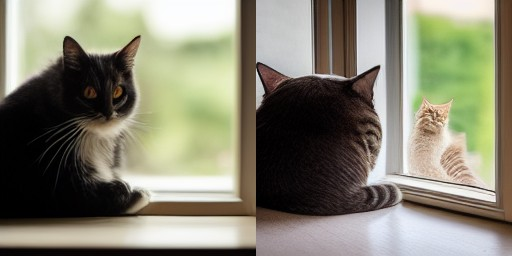

In [29]:
from my_sd15.scheduler import LCMScheduler

lcm_model = load_model("webui/miniSD", lora_path="latent-consistency/lcm-lora-sdv1-5", scheduler=LCMScheduler())
print("マージ後の重みが W + 差分と一致:", torch.allclose(lcm_model.unet.state[model_key], w + delta, atol=1e-6))

image_lcm = lcm_model.generate(prompt, seed=42, steps=4, cfg_scale=1.0)
print("タイムステップ:", lcm_model.scheduler.timesteps.tolist())
show(image_lcm, image)

4 回の U-Net 実行で、窓辺の猫の画像になりました。シードは同じですが、重みもスケジューラーも異なるため、DDIM の結果とは別の画像になります。

タイムステップは 999 から始まり、240 刻みで下ります。どの段階からでもノイズのない画像を見積もれるので、DDIM よりも大きな歩幅で進めます。

miniSD は SD 1.5 と同じ構造の派生モデルなので、SD 1.5 用に作られた LCM LoRA をそのまま適用できます。重みの差分として配布できることが、LoRA の利点です。

# SD 1.5 から現代の画像生成モデルへ

SD 1.5 以降、画像生成モデルは大きく発展しましたが、「テキストを条件ベクトルにし、潜在表現の上でノイズを取り除き、VAE で画像にする」という骨格は共通しています。

| | SD 1.5 (2022) | SDXL (2023) | SD 3 / Flux (2024) |
|---|---|---|---|
| ノイズ除去のネットワーク | U-Net | U-Net（大型化） | DiT（Transformer） |
| テキストエンコーダ | CLIP | CLIP × 2 | CLIP + T5 |
| 標準の解像度 | 512×512 | 1024×1024 | 1024×1024 |
| 潜在表現のチャネル数 | 4 | 4 | 16 |
| 画像とテキストの結び付け | Cross-Attention | Cross-Attention | 画像とテキストを 1 つの系列にして Self-Attention |

表に出てきた用語を簡単に説明します。

| 用語 | 正式名称 | 概要 |
|---|---|---|
| DiT | Diffusion Transformer | U-Net の代わりに Transformer でノイズを取り除く。潜在表現を小さなパッチに区切ってトークンとして扱う。SpatialTransformer の「画像を系列として扱う」考え方を全面的に採用した形 |
| T5 | Text-to-Text Transfer Transformer | テキストだけで訓練された大規模な言語モデル。その Encoder を使うことで、長く複雑なプロンプトを扱いやすくなる |

## DiT と LLM の違い

DiT の本体は、GPT-2 と同じ Transformer Block（LayerNorm → Attention → 残差接続 → LayerNorm → MLP → 残差接続）を積み重ねたものです。GPT-2 との違いは、主に次の点です。

| | GPT-2 | DiT |
|---|---|---|
| トークン | テキストの断片（整数 ID） | 潜在表現を 2×2 マスに区切ったパッチ（数値の並び） |
| 入力の埋め込み | WTE の表引き | Linear |
| 位置埋め込み | 学習済みの表（1 次元） | cos・sin の計算式（2 次元） |
| Attention の参照範囲 | 自分より前だけ（因果マスク） | 全トークン（マスクなし） |
| 原論文の構造との対応 | Decoder only | Encoder only |
| 出力 | 最後の位置から、次のトークンの確率分布 | 全位置から、パッチごとのノイズ予測 |
| ループ | トークンを 1 つずつ追加 | 同じ系列全体を繰り返し更新 |

- **因果マスクがない**: 画像のパッチには生成の順序がなく、全パッチを同時に更新するので、すべてのトークンが互いを参照します。SpatialTransformer の Self-Attention と同じです。
- **Encoder only に相当する**: 原論文の Transformer では、因果マスクのない側が Encoder、ある側が Decoder でした。GPT-2 が Decoder only であるのに対し、因果マスクのない DiT の本体は、BERT や ViT と同じ Encoder only の構造です。ただし役割は異なり、入力を読むのではなく画像を生成します。因果マスクなしで生成できるのは、トークンを 1 つずつ追加する代わりに、全トークンを繰り返し更新するからです。なお、Encoder only かどうかは Cross-Attention の有無では決まりません。
- **位置埋め込みは 2 次元**: パッチを 1 列に並べた通し番号では、上下に隣り合うパッチの関係が伝わりません。そこで、位置を行と列の 2 つの数で表し、それぞれをタイムステップ埋め込みと同じ cos・sin でベクトルにして連結します。計算式で作るので、画像の大きさが変わっても同じ式で求められます。
- **タイムステップとテキスト**: タイムステップは、LayerNorm の γ・β をタイムステップ埋め込みから計算することで注入します。テキストは、SD 3 / Flux ではテキストのトークンを画像のパッチと同じ系列に連結するので、Cross-Attention という別の層は不要になります。

DiT が置き換えるのは U-Net だけです。テキストエンコーダ、VAE、ノイズの予測と更新を繰り返すループは、SD 1.5 と同じ枠組みのまま残ります。

構造の違いは規模の拡大や効率の改善であり、Attention、残差接続、潜在空間、CFG、LoRA といった概念は後続のモデルでもそのまま使われています。SD 1.5 で理解した原理は、現代の画像生成モデルにも応用できます。